In [5]:
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker # used for percentage ticks
import matplotlib.colors as mcolors

# Stats
import statsmodels.api as sm

In [6]:
from analysis import *

In [17]:
scenarios = ['full_pipeline', 'full_pipeline_trunc', 'full_pipeline_MP0.95', 'no_collapse']

df2 = (
    df.assign(
        scenario=pd.Categorical(df['scenario'], categories=scenarios, ordered=True)
    )
    .query('scenario.isin(@scenarios)')
    .groupby('scenario', observed=False)
    .size()
    .reset_index(name='count')
)
df2['label'] = ['Exp. data', 'Exp. data\n(trunc.)', 'Exp. data\n(MP 0.95)', 'Exp. data\n(no cluster)']
df2

,scenario,count,label
0,full_pipeline,277,Exp. data
1,full_pipeline_trunc,200,Exp. data\n(trunc.)
2,full_pipeline_MP0.95,269,Exp. data\n(MP 0.95)
3,no_collapse,332,Exp. data\n(no cluster)


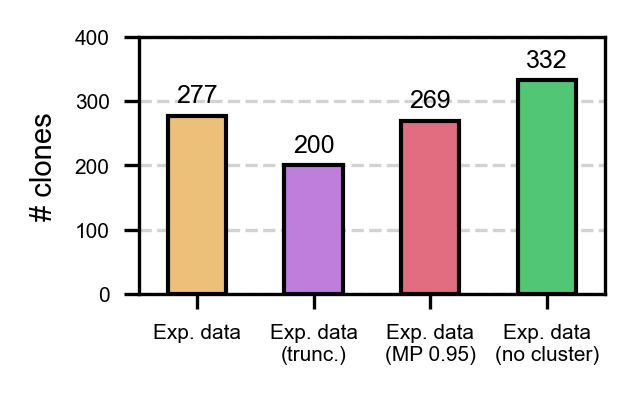

In [18]:
plt.rcParams.update(small_label_settings)
fig, ax = plt.subplots(figsize = (2.0, 1.2), dpi = 300, constrained_layout = True)

sns.barplot(data = df2, x = 'label', y = 'count', hue = 'label',
    palette = palette, legend = False, edgecolor = 'black',
    width = 0.5, zorder = 2, ax = ax
)

for patch in ax.patches:
    height = patch.get_height()
    x = patch.get_x() + patch.get_width() / 2

    ax.annotate(int(height), xy=(x, height), xytext=(0, 2),
        textcoords="offset points", ha='center', va='bottom',
        fontsize=6, color='black'
    )

ax.set_xlabel('')
ax.set_ylabel('# clones')
ax.set_ylim([0, 400])

ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray', axis = 'y', zorder=-1)

# plt.tight_layout()

filepath = os.path.join('images', 'clone_count.svg')
plt.savefig(filepath, pad_inches = 0)